# Build Regression Model Using Sequential API

If output varibale is not discrete in nature, its continuous, insequence or in time series.

In [4]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Using cached flatbuffers-25.12.19-py2.py3-none-any.whl (26 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ----------------- ---------------------- 1.0/2.4 MB 2.8 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 4.3 MB/s eta 0:00:01
   ---------------------------------------  2.4/2.4 MB 3.5 MB/s eta 0:0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogen-core 0.7.5 requires protobuf~=5.29.3, but you have protobuf 7.36.2 which is incompatible.
googleapis-common-protos 1.72.0 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
mlflow-skinny 3.3.2 requires protobuf<7,>=3.12.0, but you have protobuf 7.36.2 which is incompatible.
mlflow-tracing 3.3.2 requires protobuf<7,>=3.12.0, but you have protobuf 7.36.2 which is incompatible.
opentelemetry-proto 1.42.1 requires protobuf<7.0,>=5.0, but you have protobuf 7.36.2 which is incompatible.
streamlit 1.50.0 requires pillow<12,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
streamlit 1.50.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.2

In [3]:
%pip show tensorflow tensorflow-intel keras

Name: keras
Version: 3.11.3
Summary: Multi-backend Keras
Home-page: 
Author: 
Author-email: Keras team <keras-users@googlegroups.com>
License: Apache License 2.0
Location: C:\Users\hasan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages
Requires: absl-py, h5py, ml-dtypes, namex, numpy, optree, packaging, rich
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\hasan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


In [5]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

In [6]:
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [7]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()

In [8]:
X=housing["data"]
y=housing["target"]

In [9]:
X

array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
          37.88      , -122.23      ],
       [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
          37.86      , -122.22      ],
       [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
          37.85      , -122.24      ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
          39.43      , -121.22      ],
       [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
          39.43      , -121.32      ],
       [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
          39.37      , -121.24      ]], shape=(20640, 8))

In [10]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,))

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_Other, y_train, y_Other = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
# Split into validation and testing
X_val, X_test, y_val, y_test = train_test_split(X_Other, y_Other, test_size=0.5, random_state=42)

In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [15]:
X_train_scaled=scaler.fit_transform(X_train)
X_val_scaled=scaler.transform(X_val)
X_test_scaled=scaler.transform(X_test)

In [16]:
X_Other.shape[0]//2

2064

In [17]:
X_train.shape, X_val.shape, X_test.shape

((16512, 8), (2064, 8), (2064, 8))

In [18]:
y_train.shape, y_val.shape, y_test.shape

((16512,), (2064,), (2064,))

In [19]:
# Create Model Regression
model = keras.models.Sequential([
    keras.layers.Input(shape=X_train.shape[1:], name = "Input_Layer"),
    keras.layers.Dense(30, activation="relu", name = "HL1"),
    keras.layers.Dense(30, activation="relu", name = "HL2"),
    keras.layers.Dense(1, activation="linear", name = "Output_Layer")
    ])

In [20]:
from keras.optimizers import Adam

In [21]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [22]:
chk_pt=ModelCheckpoint("california_housing.keras",
              save_best_only=True,
              monitor="val_loss")

In [23]:
early_stop=EarlyStopping(monitor="val_loss",
                         patience=10,
                         restore_best_weights=True)

In [24]:
call_backs = [chk_pt, early_stop]

In [25]:
model.compile(loss="mse",
              optimizer=Adam(learning_rate=1e-3),
              metrics=["RootMeanSquaredError"])

In [26]:
history = model.fit(X_train_scaled, y_train, epochs=50,
          batch_size =64, validation_data=(X_val_scaled, y_val),
                    callbacks=call_backs)

Epoch 1/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - RootMeanSquaredError: 1.1266 - loss: 1.2692 - val_RootMeanSquaredError: 0.7861 - val_loss: 0.6180
Epoch 2/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - RootMeanSquaredError: 0.7055 - loss: 0.4977 - val_RootMeanSquaredError: 0.6832 - val_loss: 0.4668
Epoch 3/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - RootMeanSquaredError: 0.6511 - loss: 0.4239 - val_RootMeanSquaredError: 0.6579 - val_loss: 0.4328
Epoch 4/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.6306 - loss: 0.3977 - val_RootMeanSquaredError: 0.6475 - val_loss: 0.4192
Epoch 5/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.6192 - loss: 0.3834 - val_RootMeanSquaredError: 0.6402 - val_loss: 0.4098
Epoch 6/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.6102 - loss: 0.3723 - val_RootMeanSquaredError: 0.6316 - val_loss: 0.3989
Epoch 7/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.6004 - los

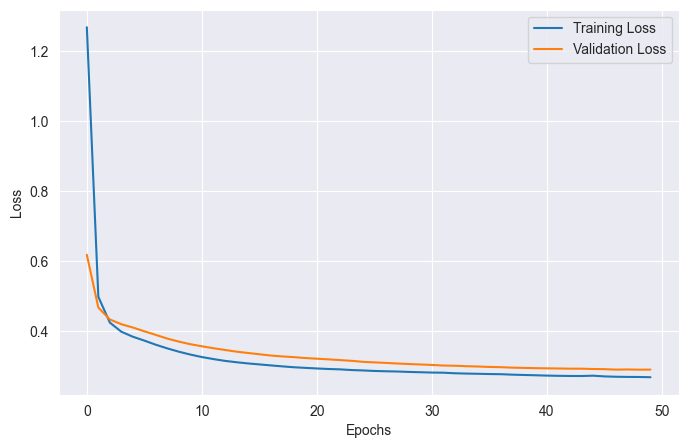

In [27]:
# Generate the loss vs val_loss

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

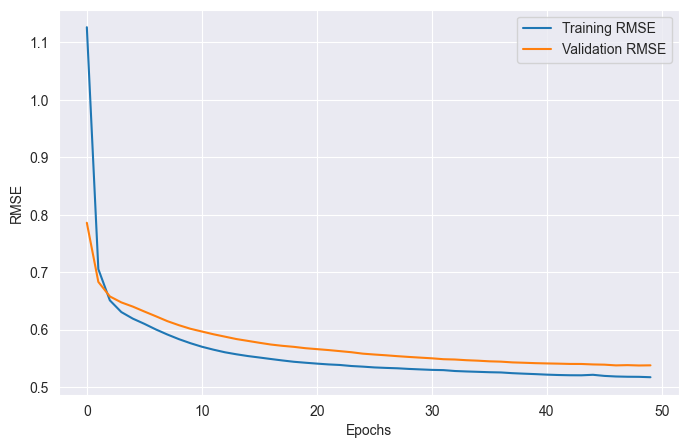

In [28]:
# Generate the accuracy vs val_accuracy Graph

plt.figure(figsize=(8,5))
plt.plot(history.history["RootMeanSquaredError"], label="Training RMSE")
plt.plot(history.history["val_RootMeanSquaredError"], label="Validation RMSE")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
plt.show()

In [29]:
from keras.models import load_model
loaded_model = load_model("california_housing.keras")

In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ HL1 (Dense)                     │ (None, 30)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL2 (Dense)                     │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,695 (14.44 KB)

 Trainable params: 1,231 (4.81 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,464 (9.63 KB)

In [31]:
from tensorflow.keras.utils import plot_model

In [32]:
plot_model(model, to_file="model.png", show_shapes=True, show_layer_names=True, dpi=80)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [37]:

# 1. Evaluate training data
train_loss, train_rmse = model.evaluate(
    X_train_scaled, y_train, verbose=0
)

y_train_pred = model.predict(X_train_scaled, verbose=0).ravel()
train_r2 = r2_score(y_train, y_train_pred)

# 2. Evaluate testing data
test_loss, test_rmse = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

y_test_pred = model.predict(X_test_scaled, verbose=0).ravel()
test_r2 = r2_score(y_test, y_test_pred)

# 3. Display results
print("TRAINING METRICS")
print(f"Train Loss:  {train_loss:.4f}")
print(f"Train RMSE:  {train_rmse:.4f}")
print(f"Train R²:    {train_r2:.4f}")

print("\nTESTING METRICS")
print(f"Test Loss:   {test_loss:.4f}")
print(f"Test RMSE:   {test_rmse:.4f}")
print(f"Test R²:     {test_r2:.4f}")

TRAINING METRICS
Train Loss:  0.2661
Train RMSE:  0.5159
Train R²:    0.8009

TESTING METRICS
Test Loss:   0.2771
Test RMSE:   0.5264
Test R²:     0.7874


In [36]:
from sklearn.metrics import r2_score

# Evaluate the model
loss, rmse = model.evaluate(X_test_scaled, y_test, verbose=0)

# Generate predictions
y_pred = model.predict(X_test_scaled).ravel()

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

print(f"Test Loss: {loss:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R² Score: {r2:.4f}")
print(f"Test R² Percentage: {r2 * 100:.2f}%")

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Test Loss: 0.28
Test RMSE: 0.53
Test R² Score: 0.7874
Test R² Percentage: 78.74%


In [33]:
loss, rmse = model.evaluate(X_test_scaled, y_test)
print(f"Test Loss: {loss:.2f}")
print(f"Test RMSE: {rmse*100:.2f}%")

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.5264 - loss: 0.2771
Test Loss: 0.28
Test RMSE: 52.64%


In [34]:
y_pred=model.predict(X_test_scaled)

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [35]:
print(f"Actual: {y_test[:5]}")
print(f"Predicted: {y_pred[:5].flatten()}")

Actual: [2.385 3.297 0.952 2.451 0.641]
Predicted: [3.2316718 2.0084746 1.4915233 2.6630867 1.1349053]
